# SciPy 特征关联分析：哪些信息与满意度有关？

**任务：二分类概率预测，正类为满意（True/1），竞赛指标为 ROC-AUC。** 本 notebook 用全量 `train.csv` 做描述性分析，不训练预测模型。原始数据和本地统计表不上传 GitHub，图像文件只导出 PDF。

阅读路径：**数据与角色 → 指标解释 → 全特征排名 → 方向与曲线 → 分层/组合 → 特征冗余 → 建模建议**。业务特征共 21 个；ID 单独诊断，label 不作为自己的预测特征。核心计算在 `code/scipy_feature_correlation/analysis.py`，绘图在同目录 `figures.py`；复用原 EDA 的分面图。

> 本文的“信息量”是经验分布上的统计量，不是准确率、因果作用或在其他特征之外的独立预测价值。不同指标数值不应直接横向比较大小。

## Block 1 · 环境与数据读取

只读取 train；test 无 label，无法计算特征与真实标签的关联。每条 CSV 记录视为一个观测，不声称是独立旅客。`Arrival Delay in Minutes` 的缺失单独列组；有序/数值统计使用各特征非缺失记录，后文显示各自的有效 n。

In [1]:
from pathlib import Path
import os
import sys
import tempfile

ROOT = Path.cwd().resolve()
if not (ROOT / 'train.csv').exists():
    raise FileNotFoundError('请从项目根目录运行，并准备 train.csv。')
sys.path.insert(0, str(ROOT / 'code'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'airline-matplotlib'))

import numpy as np
import pandas as pd
import scipy
from IPython.display import display, Markdown
from scipy_feature_correlation.analysis import catalog, run_analysis, feature_guide
from scipy_feature_correlation import figures

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
train = pd.read_csv(ROOT / 'train.csv')
OUTPUT = ROOT / 'image' / 'scipy_feature_correlation'
print(f'SciPy {scipy.__version__} | train: {train.shape} | Python: {sys.executable}')

SciPy 1.15.1 | train: (699635, 23) | Python: /Users/zhaobo/anaconda3/envs/torch/bin/python


In [2]:
# 类型按业务含义指定：评分是离散有序等级，不因 int64 就视为连续测量。
roles = catalog(train)
display(roles)
display(train.satisfaction.value_counts().rename_axis('label').to_frame('n').assign(
    proportion=lambda t: t.n / len(train)))
print('缺失：', train.isna().sum()[lambda s: s.gt(0)].to_dict())

缺失： {'Arrival Delay in Minutes': 292}


,feature,kind,dtype,n,missing,unique
0,id,id,int64,699635,0,699635
1,Age,continuous,int64,699635,0,75
2,Flight Distance,continuous,int64,699635,0,3474
3,Inflight wifi service,rating,int64,699635,0,6
4,Departure/Arrival time convenient,rating,int64,699635,0,6
5,Ease of Online booking,rating,int64,699635,0,6
6,Gate location,rating,int64,699635,0,6
7,Food and drink,rating,int64,699635,0,6
8,Online boarding,rating,int64,699635,0,6
9,Seat comfort,rating,int64,699635,0,6


,n,proportion
label,,
False,389296,0.556427
True,310339,0.443573


## Block 2 · 指标怎么算、能说明什么？

令 $Y\in\{0,1\}$；$G$ 是一个特征的离散组，$n_{g,y}$ 是列联表计数。连续变量按 **20 个分位数箱**表示；重复切点合并；延误零值独立成组，非零部分分箱；缺失作为独立组。ID 使用等宽箱检查排序漂移。分组只使用 X，不使用标签；所有后续分层复用同一批全训练集分组。

| 指标 | 计算与意义 | 适用/边界 |
|---|---|---|
| Pearson 卡方 | $\chi^2=\sum(O-E)^2/E$，$E_{g,y}=n_g n_y/N$；检验 G 与 Y 是否独立 | 统计量受样本数影响，不用它排名特征；保留期望频数诊断 |
| Cramér’s V | $V=\sqrt{\chi^2/[N\min(r-1,c-1)]}$；本任务 c=2，故 $V=\sqrt{\chi^2/N}$ | 0–1，无方向，能捕捉非单调组间差异；连续特征结果依赖分箱 |
| 互信息 MI | $I(Y;G)=\sum p(g,y)\log_2\{p(g,y)/[p(g)p(y)]\}=H(Y)-H(Y\mid G)$ | 用 `scipy.stats.entropy(base=2)` 从精确计数计算，单位 bit，非负；不是 SciPy 的多变量拟合接口 |
| 标签熵降低比例 | $I(Y;G)/H(Y)$ | 0–1；例如 0.30 表示经验条件熵比基线减少 30%，不是准确率 30% |
| 点二列相关 | 对二元 Y 与数值 X 计算 Pearson r | −1 到 1，反映线性方向；不为文字类别随意编码 |
| Spearman / Kendall τ-b | 平均秩的 Pearson 相关 / 考虑并列值的一致与不一致对数 | −1 到 1，反映单调方向；τ-b 调整并列等级；都可能漏掉 U 形 |
| 原始值 AUC | $U/(n_1n_0)=P(X_1>X_0)+\tfrac12P(X_1=X_0)$；U 用 `mannwhitneyu` 求得 | 把原始数值直接当预测分数，非模型验证 AUC；0.5 也不等于无非线性信息 |
| Somers’ D（AUC 方向） | $D(X\mid Y)=2\,AUC-1$ | SciPy 必须用 `somersd(label, score)`；本实现对低基数 X 用 SciPy 核对，对高基数 X 由 U 等价计算，避免巨大列联表 |

补充：对于本任务按 G 分组的二元 Y，原 EDA 的 grouped eta² 恰好等于 **V²**。这不表示不同指标数值都能直接比较。

卡方计算使用 `correction=False`。21 个业务特征的卡方 p 值组成一个检验族，使用 **Benjamini–Yekutieli（BY）**调整，允许检验间任意依赖。大样本下微弱关联也可能非常显著；数值显示 p=0 是浮点下溢，不是数学上等于零。推断依赖观测独立等假设，合成数据可能不满足，因此主要看效应量与曲线，不用显著性星号筛特征。

In [3]:
# 一次计算：全量统计、连续变量分箱敏感性、分层、组合和特征层次结构。
# 无抽样、无模型、无目标编码；运行生成的 CSV/JSON 放在被 gitignore 排除的 source_data/。
result = run_analysis(train, output=OUTPUT, bins=20)
summary = result['summary']
business = summary.query("kind != 'id'").sort_values('cramers_v', ascending=False)
print(f'覆盖 {len(business)} 个业务特征 + 1 个 ID；满意率 {train.satisfaction.mean():.2%}')

覆盖 21 个业务特征 + 1 个 ID；满意率 44.36%


## Block 3 · 全部 21 个业务特征：关联强度排名

先看 V 与标签熵降低比例，两者都能识别非单调关联。连续变量是**分箱后的近似**，与原始离散变量的排名不能当作无误差的统一重要性排行榜；类别数多也会增加经验统计量的向上偏差。

`supported_rate_gap` 只比较 n≥max(100, ceil(0.001N)) 的组，避免极小组主导极差；V、MI 和完整曲线仍使用全部组。相同特征同时出现在多个指标里，不意味着它们提供多份独立证据。

,feature,kind,cramers_v,mi_bits,entropy_reduction,groups,min_group_n,supported_rate_gap
9,Online boarding,rating,0.6539,0.3457,34.89%,6,9147,78.98%
0,Class,categorical,0.5557,0.2365,23.87%,3,30019,55.78%
10,Inflight wifi service,rating,0.4698,0.1761,17.77%,6,13102,67.99%
11,Inflight entertainment,rating,0.4599,0.1624,16.39%,6,1020,54.44%
1,Type of Travel,categorical,0.4444,0.1614,16.29%,2,202194,48.71%
12,Seat comfort,rating,0.4394,0.1480,14.93%,6,838,49.91%
4,Flight Distance,continuous,0.3956,0.1160,11.71%,20,33480,53.79%
13,Leg room service,rating,0.3605,0.0971,9.80%,6,1693,42.64%
14,On-board service,rating,0.3601,0.0975,9.84%,6,801,50.93%
15,Cleanliness,rating,0.3503,0.0950,9.58%,6,945,47.56%


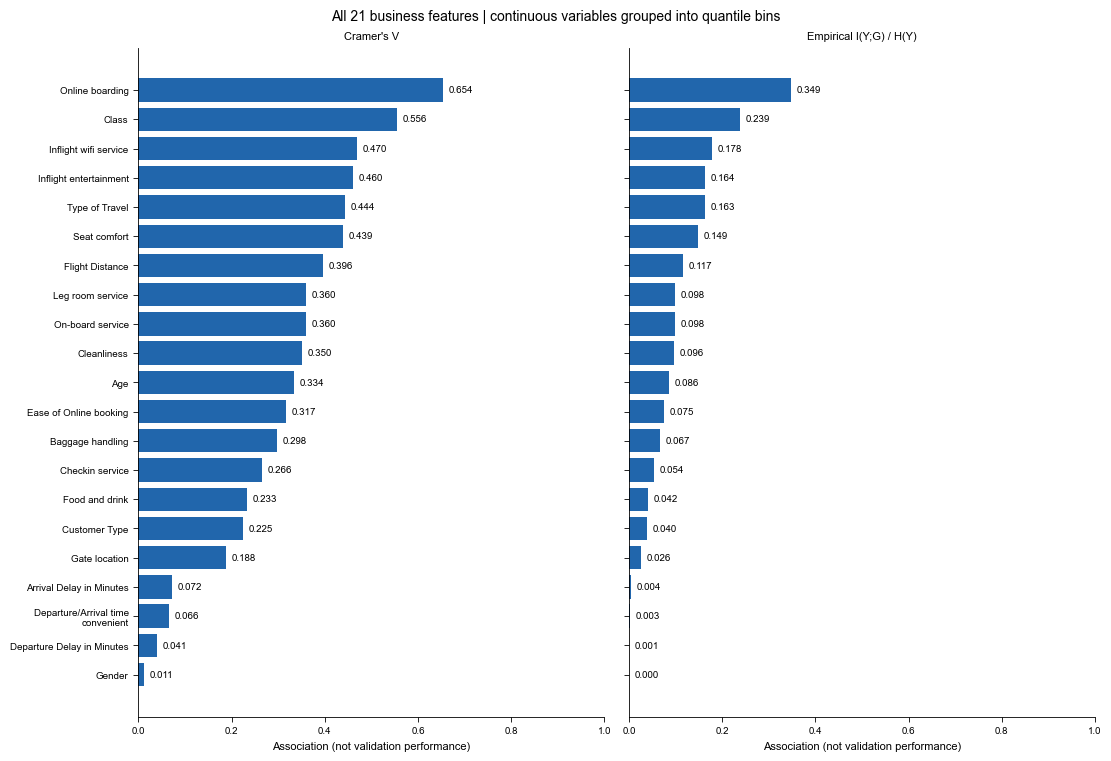

In [4]:
columns = ['feature', 'kind', 'cramers_v', 'mi_bits', 'entropy_reduction',
           'groups', 'min_group_n', 'supported_rate_gap']
display(business[columns].style.format({
    'cramers_v': '{:.4f}', 'mi_bits': '{:.4f}', 'entropy_reduction': '{:.2%}',
    'supported_rate_gap': '{:.2%}'}))
display(figures.plot_strength(result, OUTPUT))

In [5]:
# 推断诊断与效应量分开展示，不把极小 p 值当作特征强度。
display(business[['feature', 'chi2', 'dof', 'chi2_p', 'chi2_q_by',
                  'min_expected', 'expected_below5']].style.format({
    'chi2': '{:.1f}', 'chi2_p': '{:.3e}', 'chi2_q_by': '{:.3e}',
    'min_expected': '{:.2f}', 'expected_below5': '{:.2%}'}))
top = business.head(5)
display(Markdown('按 V 排名前五：' + '；'.join(
    f"**{r.feature}**（V={r.cramers_v:.3f}，熵降低={r.entropy_reduction:.1%}）"
    for r in top.itertuples()) + '。这些都是未调整其他特征的边际关联。'))

,feature,chi2,dof,chi2_p,chi2_q_by,min_expected,expected_below5
9,Online boarding,299139.0,5,0.000e+00,0.000e+00,4057.36,0.00%
0,Class,216048.1,2,0.000e+00,0.000e+00,13315.61,0.00%
10,Inflight wifi service,154439.7,5,0.000e+00,0.000e+00,5811.69,0.00%
11,Inflight entertainment,147989.2,5,0.000e+00,0.000e+00,452.44,0.00%
1,Type of Travel,138182.9,1,0.000e+00,0.000e+00,89687.74,0.00%
12,Seat comfort,135081.6,5,0.000e+00,0.000e+00,371.71,0.00%
4,Flight Distance,109513.2,19,0.000e+00,0.000e+00,14850.81,0.00%
13,Leg room service,90911.3,5,0.000e+00,0.000e+00,750.97,0.00%
14,On-board service,90718.7,5,0.000e+00,0.000e+00,355.30,0.00%
15,Cleanliness,85849.1,5,0.000e+00,0.000e+00,419.18,0.00%


按 V 排名前五：**Online boarding**（V=0.654，熵降低=34.9%）；**Class**（V=0.556，熵降低=23.9%）；**Inflight wifi service**（V=0.470，熵降低=17.8%）；**Inflight entertainment**（V=0.460，熵降低=16.4%）；**Type of Travel**（V=0.444，熵降低=16.3%）。这些都是未调整其他特征的边际关联。

## Block 4 · 方向与排序：高评分是否通常意味着满意？

下面只包括 4 个连续变量与 13 个服务评分；文字类别的数值方向没有天然意义，留空而不强行编码。`n_numeric` 是每个数值指标实际使用的样本数。原始值 AUC 不填补缺失，也不学习非线性转换；AUC<0.5 表示数值方向相反，而不是毫无用处。

**V 大而 r/ρ/D 小**，提示关系可能非单调，或评分零值有特殊含义，需要查看曲线；这只是诊断线索。各系数归一化不同，不能把“V−|ρ|”当作正式的非线性指标。

,feature,n_numeric,point_biserial,spearman,kendall_tau_b,raw_auc,somers_d_auc,somers_d_scipy
9,Online boarding,699635.0,0.5596,0.6020,0.5418,0.8404,0.6808,0.6808
10,Inflight wifi service,699635.0,0.2913,0.2870,0.2574,0.6627,0.3253,0.3253
11,Inflight entertainment,699635.0,0.4308,0.4330,0.3903,0.7445,0.4891,0.4891
12,Seat comfort,699635.0,0.4015,0.4130,0.3739,0.7321,0.4642,0.4642
4,Flight Distance,699635.0,0.3700,0.3366,0.2752,0.6956,0.3912,NaN
13,Leg room service,699635.0,0.3301,0.3324,0.3000,0.6877,0.3754,0.3754
14,On-board service,699635.0,0.3466,0.3541,0.3204,0.6993,0.3987,0.3987
15,Cleanliness,699635.0,0.3389,0.3347,0.3013,0.6894,0.3788,0.3788
5,Age,699635.0,0.2027,0.2141,0.1766,0.6244,0.2487,0.2487
16,Ease of Online booking,699635.0,0.1909,0.1919,0.1716,0.6090,0.2181,0.2181


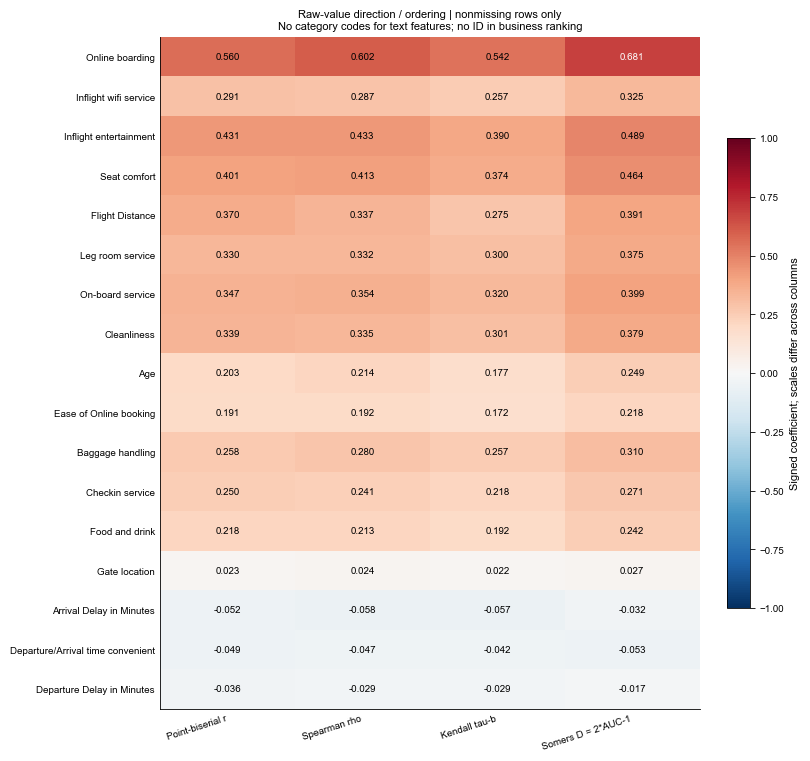

In [6]:
numeric = business.query("kind in ['continuous', 'rating']")
display(numeric[['feature', 'n_numeric', 'point_biserial', 'spearman',
                 'kendall_tau_b', 'raw_auc', 'somers_d_auc', 'somers_d_scipy']].round(4))
display(figures.plot_numeric(result, OUTPUT))

## Block 5 · 看清具体等级/区间：所有特征的满意率与样本量

蓝点是组内满意率，灰虚线是全训练集基线；误差线是**逐点 95% Wilson 二项比例区间**，不是 SD/SEM，也不是同时置信区间。下方灰条是组内 n，均从 0 开始。点在连续箱实际中位数处；连线只引导阅读，不是回归曲线。

缺失点不与数值点连线；延误 0 与非零箱不连接。延误使用 symlog 坐标（0–1 线性）；全部评分等级保留。这里查看全部特征，避免仅解释排名前几项。

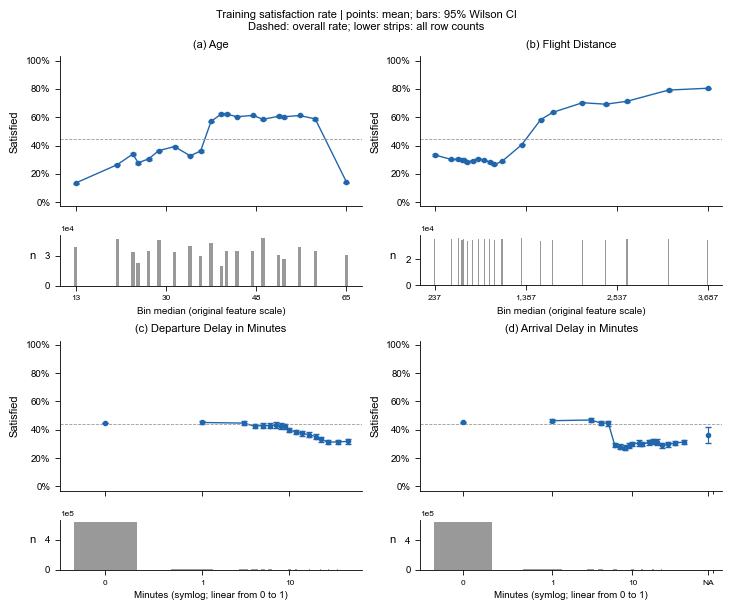

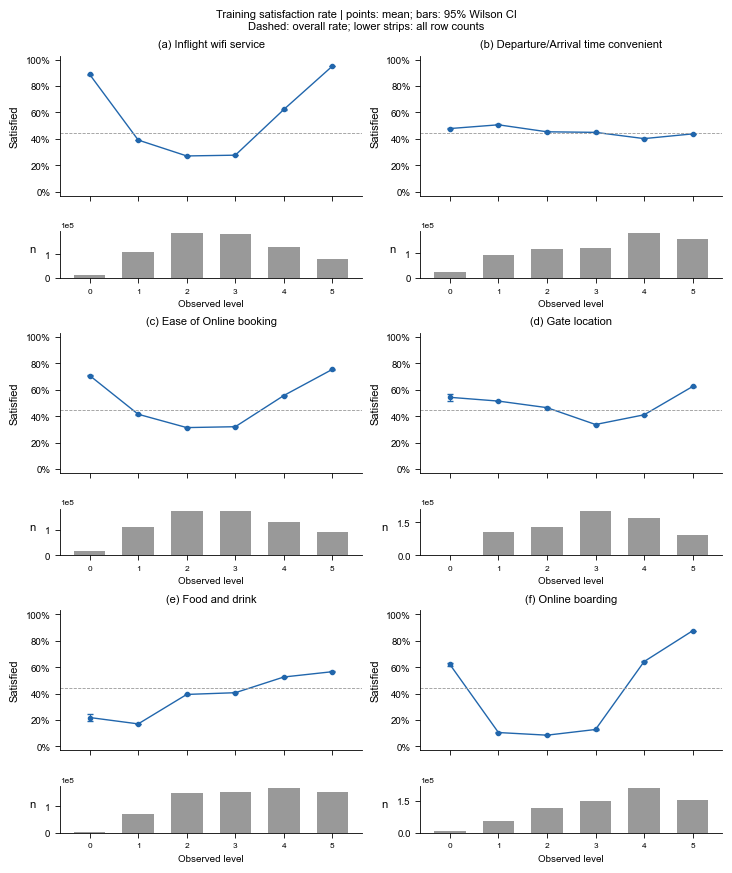

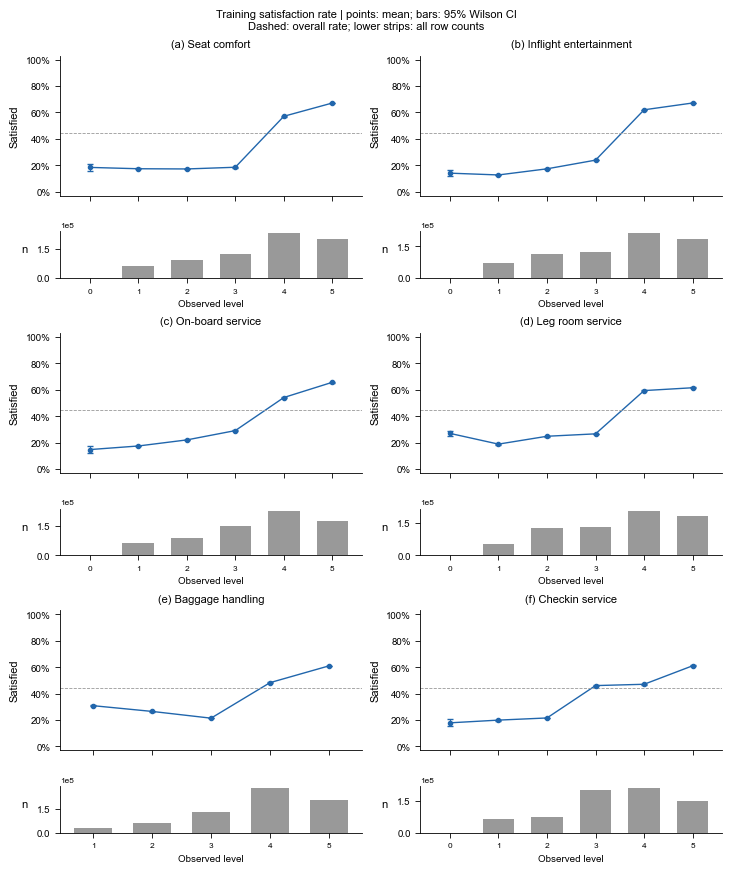

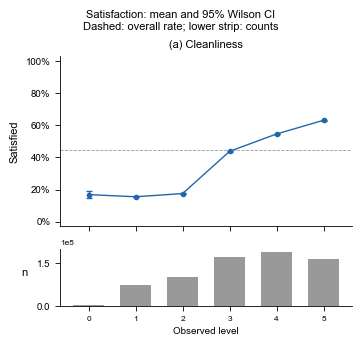

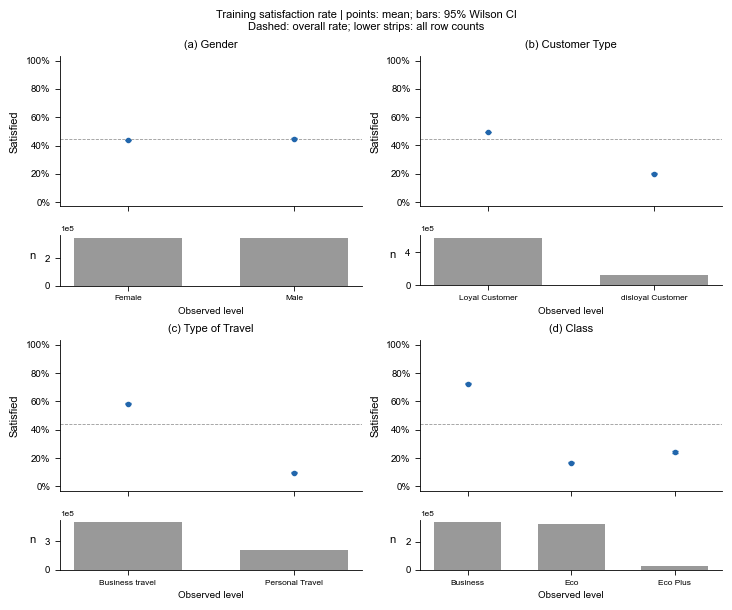

In [7]:
# profiles 的顺序：连续 1 页、评分 3 页、类别 1 页、ID 1 页。
profiles = figures.plot_profiles(result, train.satisfaction.mean(), OUTPUT)
for fig in profiles[:5]:
    display(fig)

In [8]:
# 两个典型反例：接近零的线性相关不等于没有信息；0 分也不自动等于缺失。
for feature in ['Online boarding', 'Inflight wifi service', 'Gate location']:
    display(Markdown(f'**{feature}**'))
    display(result['rates'][feature][['group', 'n', 'rate', 'low', 'high']].round(4))

**Online boarding**

,group,n,rate,low,high
0,0,9147,0.6204,0.6104,0.6303
1,1,57588,0.1053,0.1028,0.1078
2,2,119297,0.0854,0.0838,0.0870
3,3,149783,0.1284,0.1267,0.1301
4,4,210950,0.6419,0.6399,0.6440
5,5,152870,0.8751,0.8734,0.8768


**Inflight wifi service**

,group,n,rate,low,high
0,0,13102,0.8873,0.8818,0.8926
1,1,107739,0.3907,0.3878,0.3936
2,2,186870,0.2704,0.2684,0.2724
3,3,184436,0.2762,0.2742,0.2783
4,4,128136,0.6222,0.6196,0.6249
5,5,79352,0.9504,0.9488,0.9518


**Gate location**

,group,n,rate,low,high
0,0,1455,0.5430,0.5173,0.5684
1,1,104611,0.5144,0.5114,0.5174
2,2,130300,0.4647,0.4620,0.4675
3,3,202277,0.3372,0.3352,0.3393
4,4,168488,0.4105,0.4082,0.4129
5,5,92504,0.6248,0.6217,0.6279


## Block 6 · 连续变量的排名是否依赖分箱？

比较 10、20、40 个请求分位数箱。实际箱数可能因重复值而减少，延误另外保留零值/缺失组。若数值或排名明显改变，就不要依赖某一版阈值；即使稳定，也不证明真实关系已完整恢复。分箱更细可能同时提高解析度和样本内偏差。

,feature,requested_bins,groups,cramers_v,entropy_reduction,min_expected
3,Age,10,10,0.2916,0.0638,23940.5068
4,Age,20,20,0.3340,0.0856,8696.6867
5,Age,40,37,0.3361,0.0871,4609.1641
6,Flight Distance,10,10,0.3907,0.1142,30563.4911
7,Flight Distance,20,20,0.3956,0.1171,14850.8147
8,Flight Distance,40,40,0.3995,0.1195,6699.7224
9,Departure Delay in Minutes,10,10,0.0407,0.0012,2250.6880
10,Departure Delay in Minutes,20,18,0.0409,0.0013,991.3850
11,Departure Delay in Minutes,40,27,0.0413,0.0013,468.4128
12,Arrival Delay in Minutes,10,12,0.0718,0.0039,129.5232


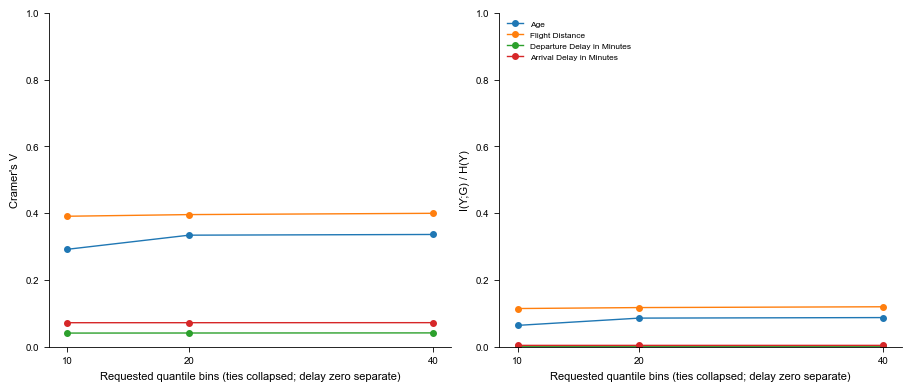

In [9]:
display(result['sensitivity'].query("feature != 'id'")[
    ['feature', 'requested_bins', 'groups', 'cramers_v', 'entropy_reduction', 'min_expected']].round(4))
display(figures.plot_sensitivity(result, OUTPUT))

## Block 7 · 按舱位和出行目的分层：总体关联会不会掩盖差异？

分别在每个 `Class`、每个 `Type of Travel` 内计算 V、MI 和样本量，所有层复用全训练集 X 分组。先看各层的 n 和满意率，再比较层内关联；少数分层表存在期望频数 <5 的格，最后的验收块单独列出，因此不对这些层作卡方显著性结论；不同基线与取值范围也会影响 V。作为分层变量本身的列显示 N/A，不伪装成零关联。

还计算只控制一个分层变量 Z 后的条件互信息：

$$I(Y;X\mid Z)=\sum_zP(z)I(Y;X\mid Z=z)$$

`conditional_entropy_reduction` 为 $I(Y;X\mid Z)/H(Y\mid Z)$：已知道 Z 后，再知道 X 能使剩余经验标签熵减少多少。**不是所有变量一起调整后的贡献，也不是平均 V**，不能据此声称去除了全部混杂。

,stratifier,stratum,n,satisfaction_rate
0,Class,Eco,327404,0.1676
1,Class,Business,342212,0.7253
2,Class,Eco Plus,30019,0.2422
60,Type of Travel,Personal Travel,202194,0.0973
61,Type of Travel,Business travel,497441,0.5843


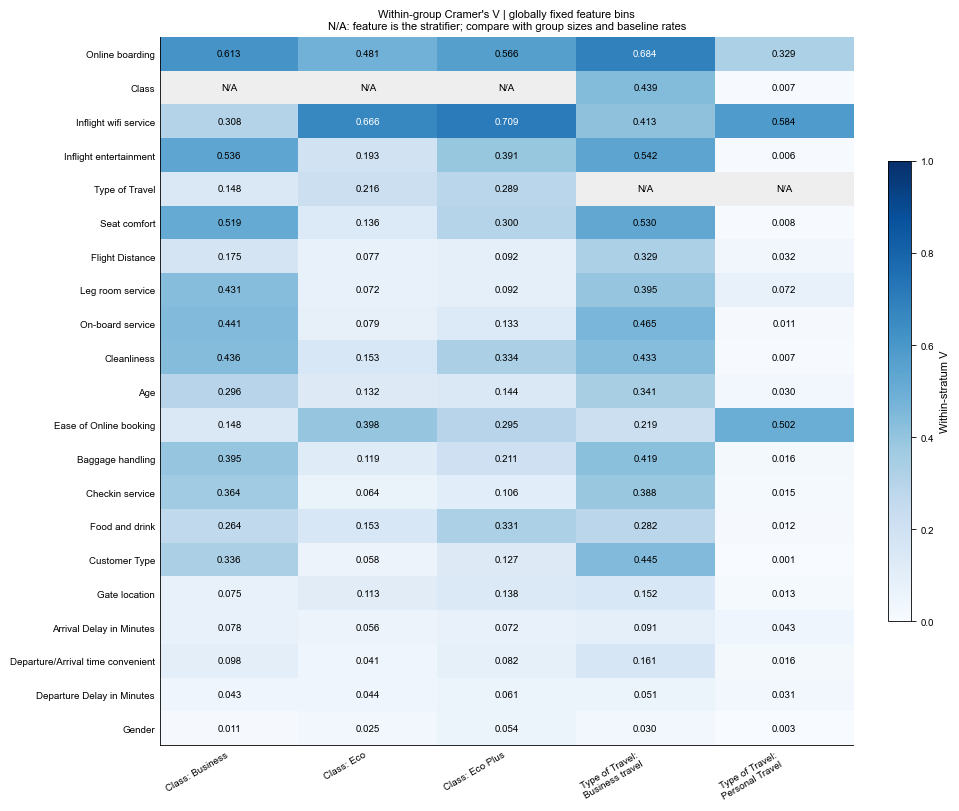

stratifier,Class,Type of Travel
feature,,
Online boarding,27.44%,34.61%
Class,N/A（分层变量自身）,12.12%
Inflight wifi service,23.40%,17.31%
Inflight entertainment,15.14%,18.99%
Type of Travel,3.37%,N/A（分层变量自身）
Seat comfort,13.10%,18.12%
Flight Distance,1.69%,6.94%
Leg room service,8.50%,9.90%
On-board service,8.98%,14.03%


In [10]:
strata = result['strata']
display(strata[['stratifier', 'stratum', 'n', 'satisfaction_rate']].drop_duplicates().round(4))
display(figures.plot_strata(result, OUTPUT))
# 覆盖每个业务特征；自身作为分层变量时不计算。
conditional = result['conditional'].pivot(
    index='feature', columns='stratifier', values='conditional_entropy_reduction').reindex(business.feature)
display(conditional.style.format('{:.2%}', na_rep='N/A（分层变量自身）'))

## Block 8 · 特征组合：已知道一列，另一列还能增加多少信息？

预先指定四组组合：登机×Wi-Fi、登机×舱位、Wi-Fi×舱位、舱位×出行目的。把原始离散等级组合成联合组，计算 $I(Y;A,B)$，再用链式法则：

$$I(Y;A\mid B)=I(Y;A,B)-I(Y;B)$$

`gain_a_given_b_bits` 是已知 B 后 A 的额外经验信息；反向增量另列。**联合 MI 比单变量高并不能证明存在交互作用**：即使只有可相加的信息也可能增长；细分组合还会引入估计偏差。真正的交互增益需后续在相同验证划分下比较含/不含交互的模型。

热图颜色是满意率，每格标注 n；稀疏格不应该被当成可靠规律。

,feature_a,feature_b,mi_a_bits,mi_b_bits,joint_mi_bits,gain_a_given_b_bits,gain_b_given_a_bits,joint_v,joint_groups
0,Online boarding,Inflight wifi service,0.3457,0.1761,0.4266,0.2505,0.0808,0.7090,36
1,Online boarding,Class,0.3457,0.2365,0.4435,0.2070,0.0978,0.7270,18
2,Inflight wifi service,Class,0.1761,0.2365,0.4130,0.1765,0.2369,0.6926,18
3,Class,Type of Travel,0.2365,0.1614,0.2620,0.1005,0.0254,0.5766,6


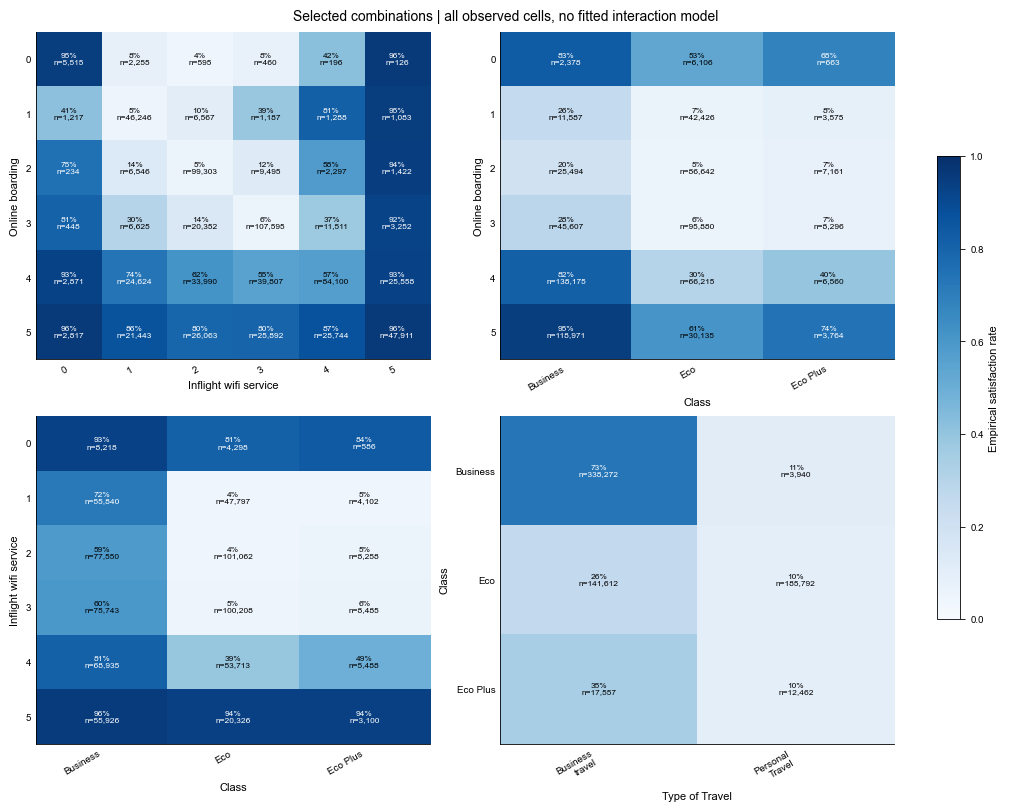

In [11]:
display(result['joint'].round(4))
display(figures.plot_joint(result, OUTPUT))

## Block 9 · 特征之间的层次关系：哪些可能携带相似信息？

用全部 21 个业务特征的两两 Cramér’s V 构成矩阵，连续变量仍使用既定分箱。以 `1−V` 为差异度，使用 SciPy **average linkage** 聚类并显示树状图；没有使用 label，也不把它当作保证欧氏性质的距离，因此不使用要求欧氏距离的 Ward。

高关联的两列是冗余检查候选，不能直接删除其中一列；它们仍可能分别提供条件信息。这种“特征层次聚类”与“旅客嵌套在航班中的多层模型”不是同一回事。本数据缺少真实航班/航空公司等分组 ID，暂不建立多层 Logistic 模型。

,feature_a,feature_b,cramers_v
47,Inflight wifi service,Ease of Online booking,0.7051
22,Class,Type of Travel,0.6027
62,Inflight entertainment,Cleanliness,0.5645
58,Inflight entertainment,Seat comfort,0.5590
93,Seat comfort,Cleanliness,0.5585
148,Cleanliness,Food and drink,0.5405
171,Ease of Online booking,Departure/Arrival time convenient,0.5327
67,Inflight entertainment,Food and drink,0.5311
98,Seat comfort,Food and drink,0.5135
1,Online boarding,Inflight wifi service,0.4933


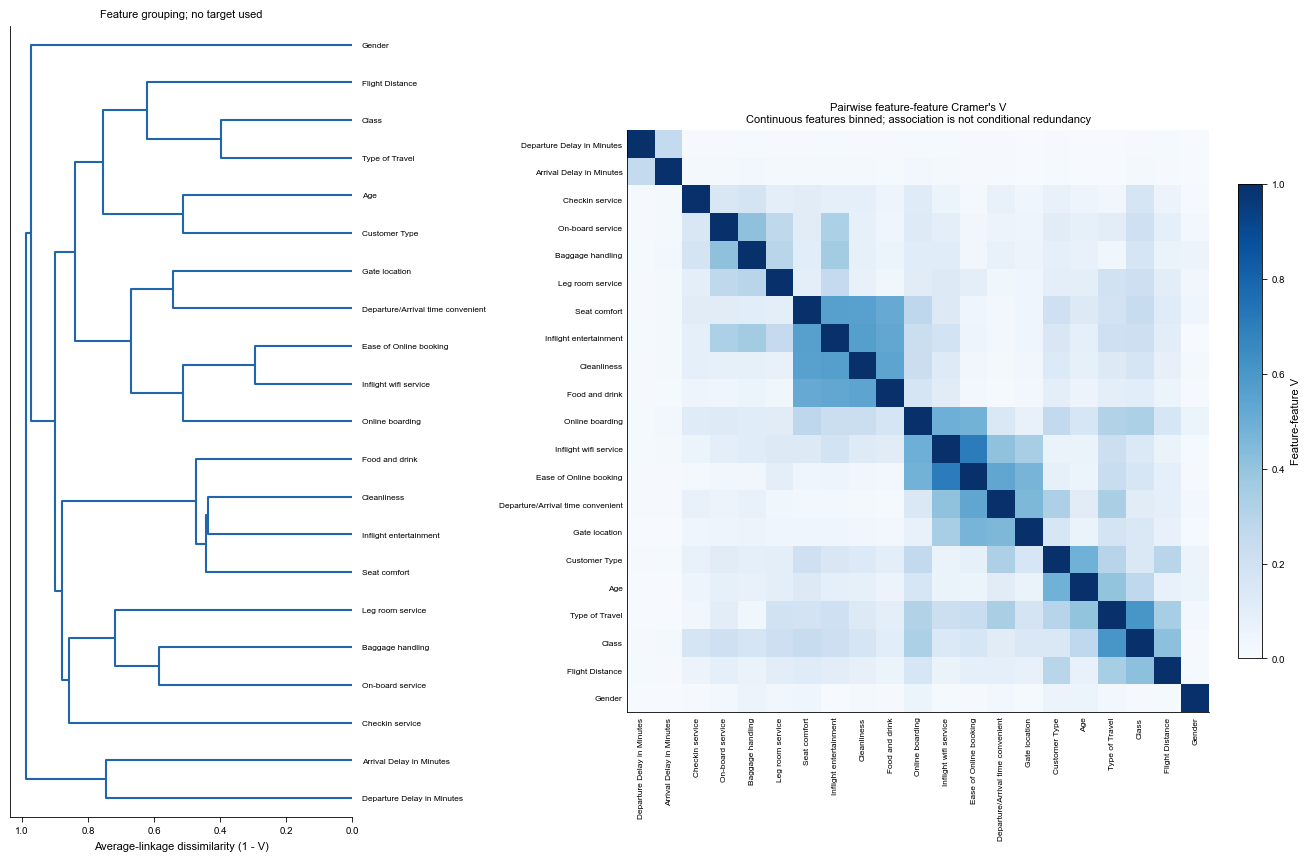

In [12]:
display(result['redundancy'].head(15).round(4))
display(figures.plot_redundancy(result, OUTPUT))

## Block 10 · ID 单独诊断

不把近乎唯一的 ID 当原始类别计算 V，否则每个 ID 都能“完美解释”一个训练标签，结论没有预测意义。这里只检查等宽 ID 区间的标签漂移和原始 ID 的排序关系；ID 不进入业务排名、冗余树或特征组合。

即使 ID 关联接近零，也不能证明数据划分一定随机；若发现关联，也不能证明它能迁移到测试集。

,feature,groups,cramers_v,entropy_reduction,spearman,raw_auc
8,id,20,0.00489,0.00002,0.00012,0.50007


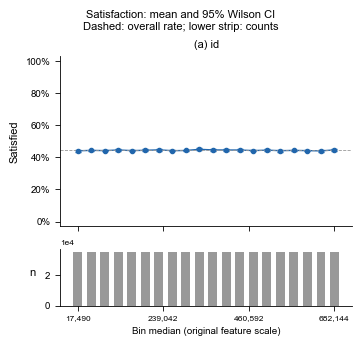

In [13]:
display(summary.query("kind == 'id'")[
    ['feature', 'groups', 'cramers_v', 'entropy_reduction', 'spearman', 'raw_auc']].round(5))
display(profiles[-1])

## Block 11 · 每个特征对后续建模的意义

下面覆盖全部 21 个业务特征，按边际 V 排序。建议是下一步需要验证的编码/非线性/交互假设，不是已经证明的模型收益。类别行的原始 AUC 显示为空，是因为没有天然数值顺序，不是没有信息。

- **较强边际信息**：优先验证能否转化为验证集 AUC；不要把相关评分的贡献相加。
- **弱边际但有非单调/条件信息**：保留做模型对照；不能仅按 Pearson 或 V 阈值删列。
- **缺失/零值/长尾**：按业务和分组结果保留，填补与编码只在训练折内拟合。
- **真正的增量预测价值**：后续使用固定划分或交叉验证，比较加入/移除特征或特征组后的 AUC，并检查结果稳定性。全训练集分组满意率不可直接作为验证集目标编码。

In [14]:
guide = feature_guide(result)
display(guide.style.format({'cramers_v': '{:.3f}', 'entropy_reduction': '{:.2%}',
                           'raw_auc': '{:.3f}'}, na_rep='—'))

,feature,kind,cramers_v,entropy_reduction,raw_auc,建模检查建议
9,Online boarding,rating,0.654,34.89%,0.840,优先：比较等级类别编码与数值编码；检查 0 和 3→4 跳变。
0,Class,categorical,0.556,23.87%,—,类别编码；检查分层基线与评分交互。
10,Inflight wifi service,rating,0.470,17.77%,0.663,优先：保留 0 特殊组；不要先加单调约束；检查与舱位交互。
11,Inflight entertainment,rating,0.460,16.39%,0.745,比较非线性/类别编码；检查与座椅、清洁的冗余。
1,Type of Travel,categorical,0.444,16.29%,—,类别编码；检查与舱位及客户类型的组合。
12,Seat comfort,rating,0.439,14.93%,0.732,比较非线性/类别编码；检查与娱乐、清洁的冗余。
4,Flight Distance,continuous,0.396,11.71%,0.696,检查阈值及舱位混杂；比较非线性表达。
13,Leg room service,rating,0.360,9.80%,0.688,比较等级类别编码与数值编码；检查分组曲线及冗余。
14,On-board service,rating,0.360,9.84%,0.699,比较等级类别编码与数值编码；检查分组曲线及冗余。
15,Cleanliness,rating,0.350,9.58%,0.689,比较等级类别编码与数值编码；检查分组曲线及冗余。


## Block 12 · 覆盖、守恒与输出验收

该 notebook 不运行 MGC（近 70 万行的距离矩阵成本过高），也不使用对输入并列值处理敏感的 Chatterjee ξ 作为离散评分主排名。不把更多高度重复的系数堆在一起；当前已覆盖线性、排序、非单调、分层条件信息、组合和特征间关系。

独立的 `check_analysis.py` 另外验证：独立/完美关联、U 形反例、并列值的 AUC/Somers 方向、缺失与 Wilson 区间、XOR 的联合/条件互信息。下列检查针对本次真实全量运行。

In [15]:
from scipy_feature_correlation.check_analysis import check
check()
assert set(summary.feature) == set(train.columns) - {'satisfaction'}
assert len(business) == 21 and summary.n.eq(len(train)).all()
for feature, table in result['rates'].items():
    assert table.n.sum() == len(train)
    assert table.positive.sum() == train.satisfaction.sum()
assert np.isclose(summary.loc[summary.feature.eq('Arrival Delay in Minutes'), 'n_numeric'].iloc[0],
                  train['Arrival Delay in Minutes'].notna().sum())
assert result['feature_matrix'].shape == (21, 21)
assert result['strata'].n.gt(0).all()
# 稀疏期望格是推断限制，不是假定所有层都满足卡方近似。
display(result['strata'].query('expected_below5 > 0')[
    ['feature', 'stratifier', 'stratum', 'min_expected', 'expected_below5']].round(4))
pdfs = sorted(OUTPUT.glob('*.pdf'))
assert len(pdfs) == 12 and all(p.read_bytes().startswith(b'%PDF-') for p in pdfs)
assert not any(p.suffix.lower() in {'.png', '.jpg', '.jpeg'} for p in OUTPUT.rglob('*'))
print(f'PASS：22 列覆盖、样本/正类守恒、有效 n、分层频数、12 份 PDF；输出：{OUTPUT}')

PASS: independence/perfect/U-shape, ties and AUC orientation, missing/Wilson, XOR/conditional MI.
PASS：22 列覆盖、样本/正类守恒、有效 n、分层频数、12 份 PDF；输出：/Users/zhaobo/Desktop/predicting airline satisfaction/image/scipy_feature_correlation


,feature,stratifier,stratum,min_expected,expected_below5
17,Flight Distance,Class,Eco Plus,1.4531,0.075
50,Arrival Delay in Minutes,Class,Eco Plus,3.1483,0.025
70,Flight Distance,Type of Travel,Personal Travel,3.8905,0.025


## 官方资料与复现

核心环境：项目指定的 `/Users/zhaobo/anaconda3/envs/torch/bin/python`（当前 SciPy 1.15.1），依赖 pandas、NumPy、SciPy、Matplotlib、IPython/Jupyter。详细版本与参数自动写入 `image/scipy_feature_correlation/source_data/runtime.json`。

- [Cramér’s V / association](https://docs.scipy.org/doc/scipy-1.15.1/reference/generated/scipy.stats.contingency.association.html)
- [卡方独立性检验](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)
- [Shannon 熵 / KL divergence](https://docs.scipy.org/doc/scipy-1.15.1/reference/generated/scipy.stats.entropy.html)
- [点二列相关](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pointbiserialr.html)
- [Spearman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)、[Kendall τ-b](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html)
- [Somers’ D 的输入方向](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.somersd.html)、[Mann–Whitney U](https://docs.scipy.org/doc/scipy-1.15.1/reference/generated/scipy.stats.mannwhitneyu.html)
- [多重检验 BY](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html)
- [层次聚类与距离要求](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)
- [MGC 的适用范围](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multiscale_graphcorr.html)、[ξ 与并列值](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chatterjeexi.html)

全部计算来自 train；没有 test 标签、外部原始数据或训练模型。重新执行全部单元即可重建分析；本地 `source_data/` 保存全特征表、分组率、分层/组合、特征矩阵和树结构，PDF 可直接打开分享。Notebook 内嵌预览保留，不额外写 PNG/JPG 文件。